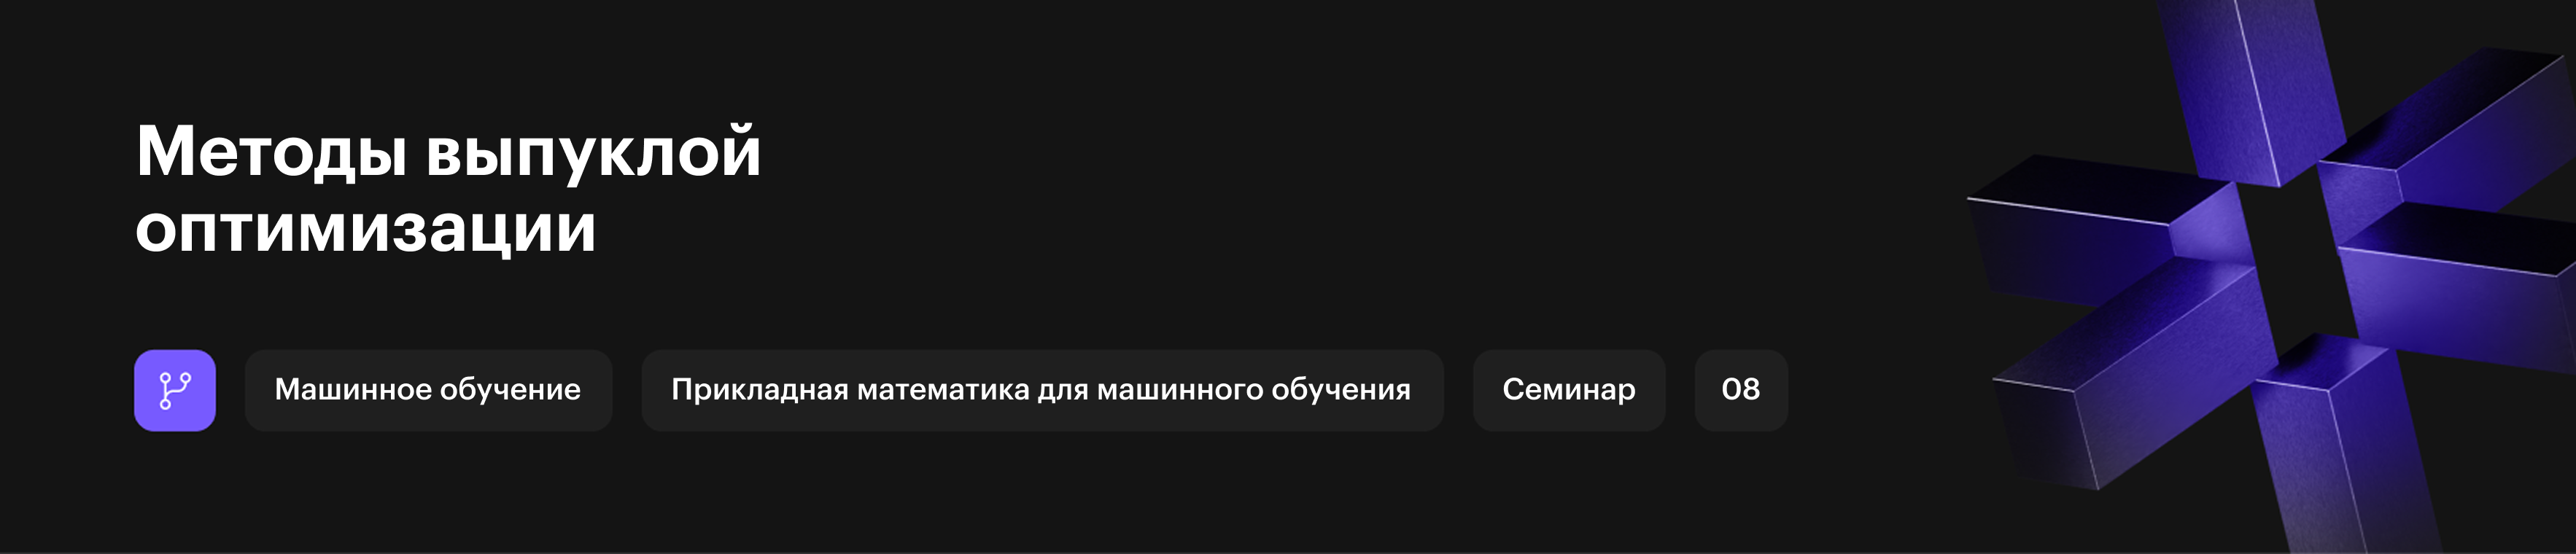

# Задания

<font color='DarkOrange'>**Задание 1.**</font>
Производитель хочет создать цилиндрическую банку объёмом 500 мл (0,5 л), которая будет иметь минимальную площадь поверхности. Это позволит сэкономить на материале при сохранении нужного объёма.

Из геометрии мы знаем:

объём цилиндра — V = π × r² × h = 500 (см³),
площадь поверхности — S = 2πr² + 2πrh,

где r — радиус основания (см),
h — высота банки (см).

**Математическая постановка**

Нужно найти такие r и h, которые минимизируют функцию
S(r, h) = 2πr² + 2πrh

при ограничении
π × r² × h = 500.

**Преобразование в задачу безусловной оптимизации**

Выразим h через r из уравнения объёма:
h = 500 ÷ (π × r²).

Подставим в формулу площади:
S(r) = 2πr² + 2πr × [500 ÷ (π × r²)] = 2πr² + 1000 ÷ r.

Теперь у нас есть функция одной переменной S(r), которую нужно минимизировать.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

V_target = 500
pi = np.pi

def surface_area(r):
    return 2 * pi * r**2 + 2 * V_target / r

def gradient(r):
    return 4 * pi * r - 2 * V_target / r**2

def s_min(r = 5.0, num_iterations = 200, learning_rate = 0.001, tolerance = 1e-6):
  r_history = [r]
  s_history = [surface_area(r)]

  for i in range(num_iterations):
      grad = gradient(r)

      r_new = r - learning_rate * grad

      if abs(r_new - r) < tolerance:
          print(f"Сходимость достигнута на итерации {i}")
          break

      r = r_new
      r_history.append(r)
      s_history.append(surface_area(r))

      if i % 20 == 0:
          print(f"Итерация {i}: r = {r:.4f} см, S = {surface_area(r):.2f} см²")
  return r, r_history, s_history

def plots(r, r_history, s_history):
  h = V_target / (pi * r**2)

  print(f"Оптимальный радиус: r = {r:.2f} см")
  print(f"Оптимальная высота: h = {h:.2f} см")
  print(f"Минимальная площадь: S = {surface_area(r):.2f} см²")
  print(f"Отношение h/r = {h/r:.2f}")

  # Визуализация результатов (3 графика в одном ряду, аналогично заданию 2)
  plt.figure(figsize=(15, 5))

  # 1. Изменение радиуса по итерациям
  plt.subplot(1, 3, 1)
  plt.plot(r_history, 'g-', linewidth=2)
  plt.title('Оптимизация радиуса (r)')
  plt.xlabel('Итерация')
  plt.ylabel('Радиус r (см)')
  plt.grid(True)

  # 2. Снижение площади поверхности
  plt.subplot(1, 3, 2)
  plt.plot(s_history, 'b-', linewidth=2)
  plt.title('Снижение площади поверхности')
  plt.xlabel('Итерация')
  plt.ylabel('Площадь S (см²)')
  plt.grid(True)

  # 3. Зависимость площади от радиуса
  plt.subplot(1, 3, 3)
  r_values = np.linspace(2, 8, 100)
  s_values = surface_area(r_values)
  plt.plot(r_values, s_values, 'r-', linewidth=2, label='S(r)')
  plt.axvline(r, color='black', linestyle='--', label=f'Найденный оптимум r = {r:.2f} см')
  plt.scatter(r, surface_area(r), color='black', zorder=5)
  plt.title('Зависимость площади от r')
  plt.xlabel('Радиус r (см)')
  plt.ylabel('Площадь S (см²)')
  plt.legend()
  plt.grid(True)

  plt.tight_layout()
  plt.show()

Итерация 0: r = 4.9772 см, S = 356.57 см²
Итерация 20: r = 4.6401 см, S = 350.79 см²
Итерация 40: r = 4.4650 см, S = 349.23 см²
Итерация 60: r = 4.3788 см, S = 348.85 см²
Итерация 80: r = 4.3376 см, S = 348.76 см²
Итерация 100: r = 4.3182 см, S = 348.74 см²
Итерация 120: r = 4.3091 см, S = 348.74 см²
Итерация 140: r = 4.3049 см, S = 348.73 см²
Итерация 160: r = 4.3030 см, S = 348.73 см²
Итерация 180: r = 4.3021 см, S = 348.73 см²
Итерация 200: r = 4.3016 см, S = 348.73 см²
Итерация 220: r = 4.3014 см, S = 348.73 см²
Итерация 240: r = 4.3013 см, S = 348.73 см²
Итерация 260: r = 4.3013 см, S = 348.73 см²
Сходимость достигнута на итерации 270
Оптимальный радиус: r = 4.30 см
Оптимальная высота: h = 8.60 см
Минимальная площадь: S = 348.73 см²
Отношение h/r = 2.00


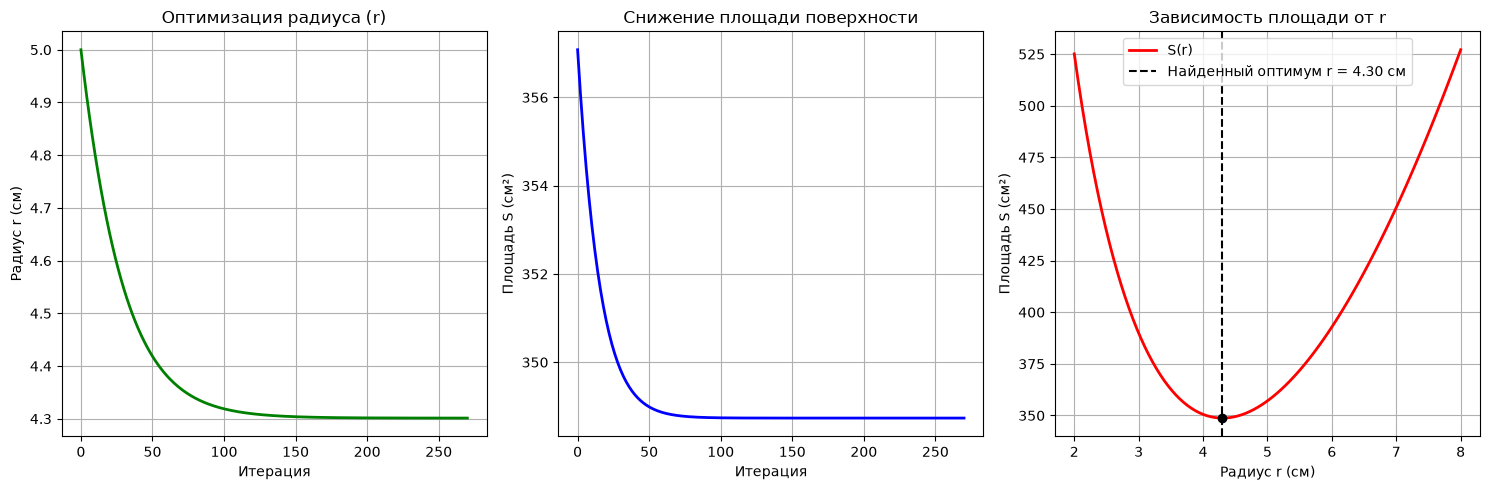

In [6]:
#TODO
r, r_history, s_history = s_min(num_iterations=1000)
plots(r, r_history, s_history)


<font color='DarkOrange'>**Задание 2.**</font> **Оптимизация логистической функции потерь (logistic loss) с использованием условий Армихо — Вульфа.**

Представь, что ты разрабатываешь простейший классификатор в машинном обучении. У тебя есть одномерный признак $x$ и бинарный класс $y \in \{-1, 1\}$.
Мы хотим найти оптимальный вес $w$, который минимизирует регуляризованную логистическую функцию потерь на обучающей выборке:

$$L(w) = \frac{1}{N} \sum_{i=1}^{N} \ln(1 + e^{-y_i w x_i}) + \frac{\lambda}{2} w^2.$$

Для простоты сгенерируем модельный датасет и исследуем сходимость метода градиентного спуска с **адаптивным шагом по условиям Армихо — Вульфа**.

**Необходимо:**

1) построить график изменения веса $w$ и функции потерь по итерациям;

2) исследовать влияние параметров условий Вульфа ($c_1$ и $c_2$) на скорость сходимости метода (количество итераций). Как ведут себя жёсткие требования к убыванию по сравнению со слабыми?

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация простых модельных данных для классификации
np.random.seed(42)
X_data = np.concatenate([np.random.normal(-2, 0.5, 15), np.random.normal(2, 0.5, 15)])
y_data = np.concatenate([-np.ones(15), np.ones(15)])
lmbda = 0.1  # Коэффициент регуляризации

# Определение функции потерь и её градиента по весу w
def loss(w):
    # w — одномерный массив [w]
    margin = y_data * w[0] * X_data
    return np.mean(np.log(1 + np.exp(-margin))) + 0.5 * lmbda * w[0]**2

def grad_loss(w):
    margin = y_data * w[0] * X_data
    # Производная log(1 + e^-z) по w равна -y * x / (1 + e^z)
    numerator = -y_data * X_data
    denominator = 1 + np.exp(margin)
    return np.array([np.mean(numerator / denominator) + lmbda * w[0]])

# Поиск шага по условиям Армихо — Вульфа
def line_search_wolfe(w, p, c1=1e-4, c2=0.9, max_iter=50):
    alpha = 1.0
    alpha_min = 0.0
    alpha_max = np.inf

    lw = loss(w)
    gw = grad_loss(w)
    g_p = np.dot(gw, p)

    for _ in range(max_iter):
        w_next = w + alpha * p
        lw_next = loss(w_next)

        # Условие Армихо
        if lw_next > lw + c1 * alpha * g_p:
            alpha_max = alpha
            alpha = 0.5 * (alpha_min + alpha_max)
        else:
            # Условие Вульфа
            gw_next = grad_loss(w_next)
            g_p_next = np.dot(gw_next, p)
            if g_p_next < c2 * g_p:
                alpha_min = alpha
                if alpha_max == np.inf:
                    alpha = 2.0 * alpha
                else:
                    alpha = 0.5 * (alpha_min + alpha_max)
            else:
                break
    return alpha

# Алгоритм оптимизации
def fit_logistic_regression(w_start, c1=1e-4, c2=0.9, num_iterations=100, tolerance=1e-5):
    w = np.array([w_start], dtype=float)
    w_history = [w[0]]
    loss_history = [loss(w)]

    for i in range(num_iterations):
        grad = grad_loss(w)
        if np.abs(grad[0]) < tolerance:
            break

        p = -grad
        alpha = line_search_wolfe(w, p, c1=c1, c2=c2)

        w = w + alpha * p
        w_history.append(w[0])
        loss_history.append(loss(w))

    return w[0], w_history, loss_history

c1 = 0.0001, c2 = 0.9
Количество итераций: 25
Вес: 1.356465
Функция потерь: 0.176356

c1 = 0.1, c2 = 0.9
Количество итераций: 25
Вес: 1.356465
Функция потерь: 0.176356

c1 = 0.5, c2 = 0.9
Количество итераций: 25
Вес: 1.356465
Функция потерь: 0.176356

c1 = 0.8, c2 = 0.9
Количество итераций: 32
Вес: 1.356470
Функция потерь: 0.176356

c1 = 0.0001, c2 = 0.5
Количество итераций: 10
Вес: 1.356474
Функция потерь: 0.176356

c1 = 0.0001, c2 = 0.1
Количество итераций: 7
Вес: 1.356478
Функция потерь: 0.176356



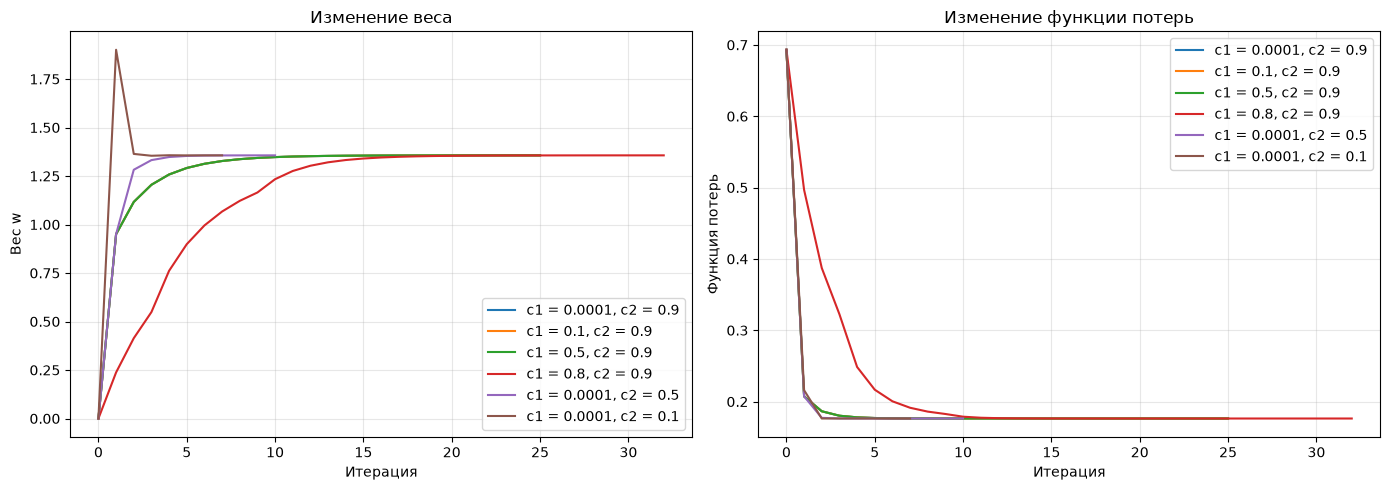

In [8]:
#TODO
parameters = [
    (1e-4, 0.9),
    (0.1, 0.9),
    (0.5, 0.9),
    (0.8, 0.9),
    (1e-4, 0.5),
    (1e-4, 0.1),
]

plt.figure(figsize=(14, 5))

for c1, c2 in parameters:
    w, w_history, loss_history = fit_logistic_regression(
        w_start=0, c1=c1, c2=c2, num_iterations=1000
    )
    iterations = len(w_history) - 1
    label = f"c1 = {c1}, c2 = {c2}"

    print(label)
    print("Количество итераций:", iterations)
    print(f"Вес: {w:.6f}")
    print(f"Функция потерь: {loss_history[-1]:.6f}")
    print()

    plt.subplot(1, 2, 1)
    plt.plot(w_history, label=label)

    plt.subplot(1, 2, 2)
    plt.plot(loss_history, label=label)

plt.subplot(1, 2, 1)
plt.xlabel("Итерация")
plt.ylabel("Вес w")
plt.title("Изменение веса")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.xlabel("Итерация")
plt.ylabel("Функция потерь")
plt.title("Изменение функции потерь")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


При c2 = 0.9 значения c1 = 0.0001, 0.1 и 0.5 дали 25 итераций, а c1 = 0.8 — 32. Увеличение c1 делает требование к убыванию строже и в этом эксперименте замедляет сходимость.

При c1 = 0.0001 уменьшение c2 с 0.9 до 0.5 и 0.1 сократило число итераций с 25 до 10 и 7. Меньшее c2 усиливает условие кривизны и требует большего прогресса вдоль направления спуска. Во всех случаях получен вес около 1.3565.

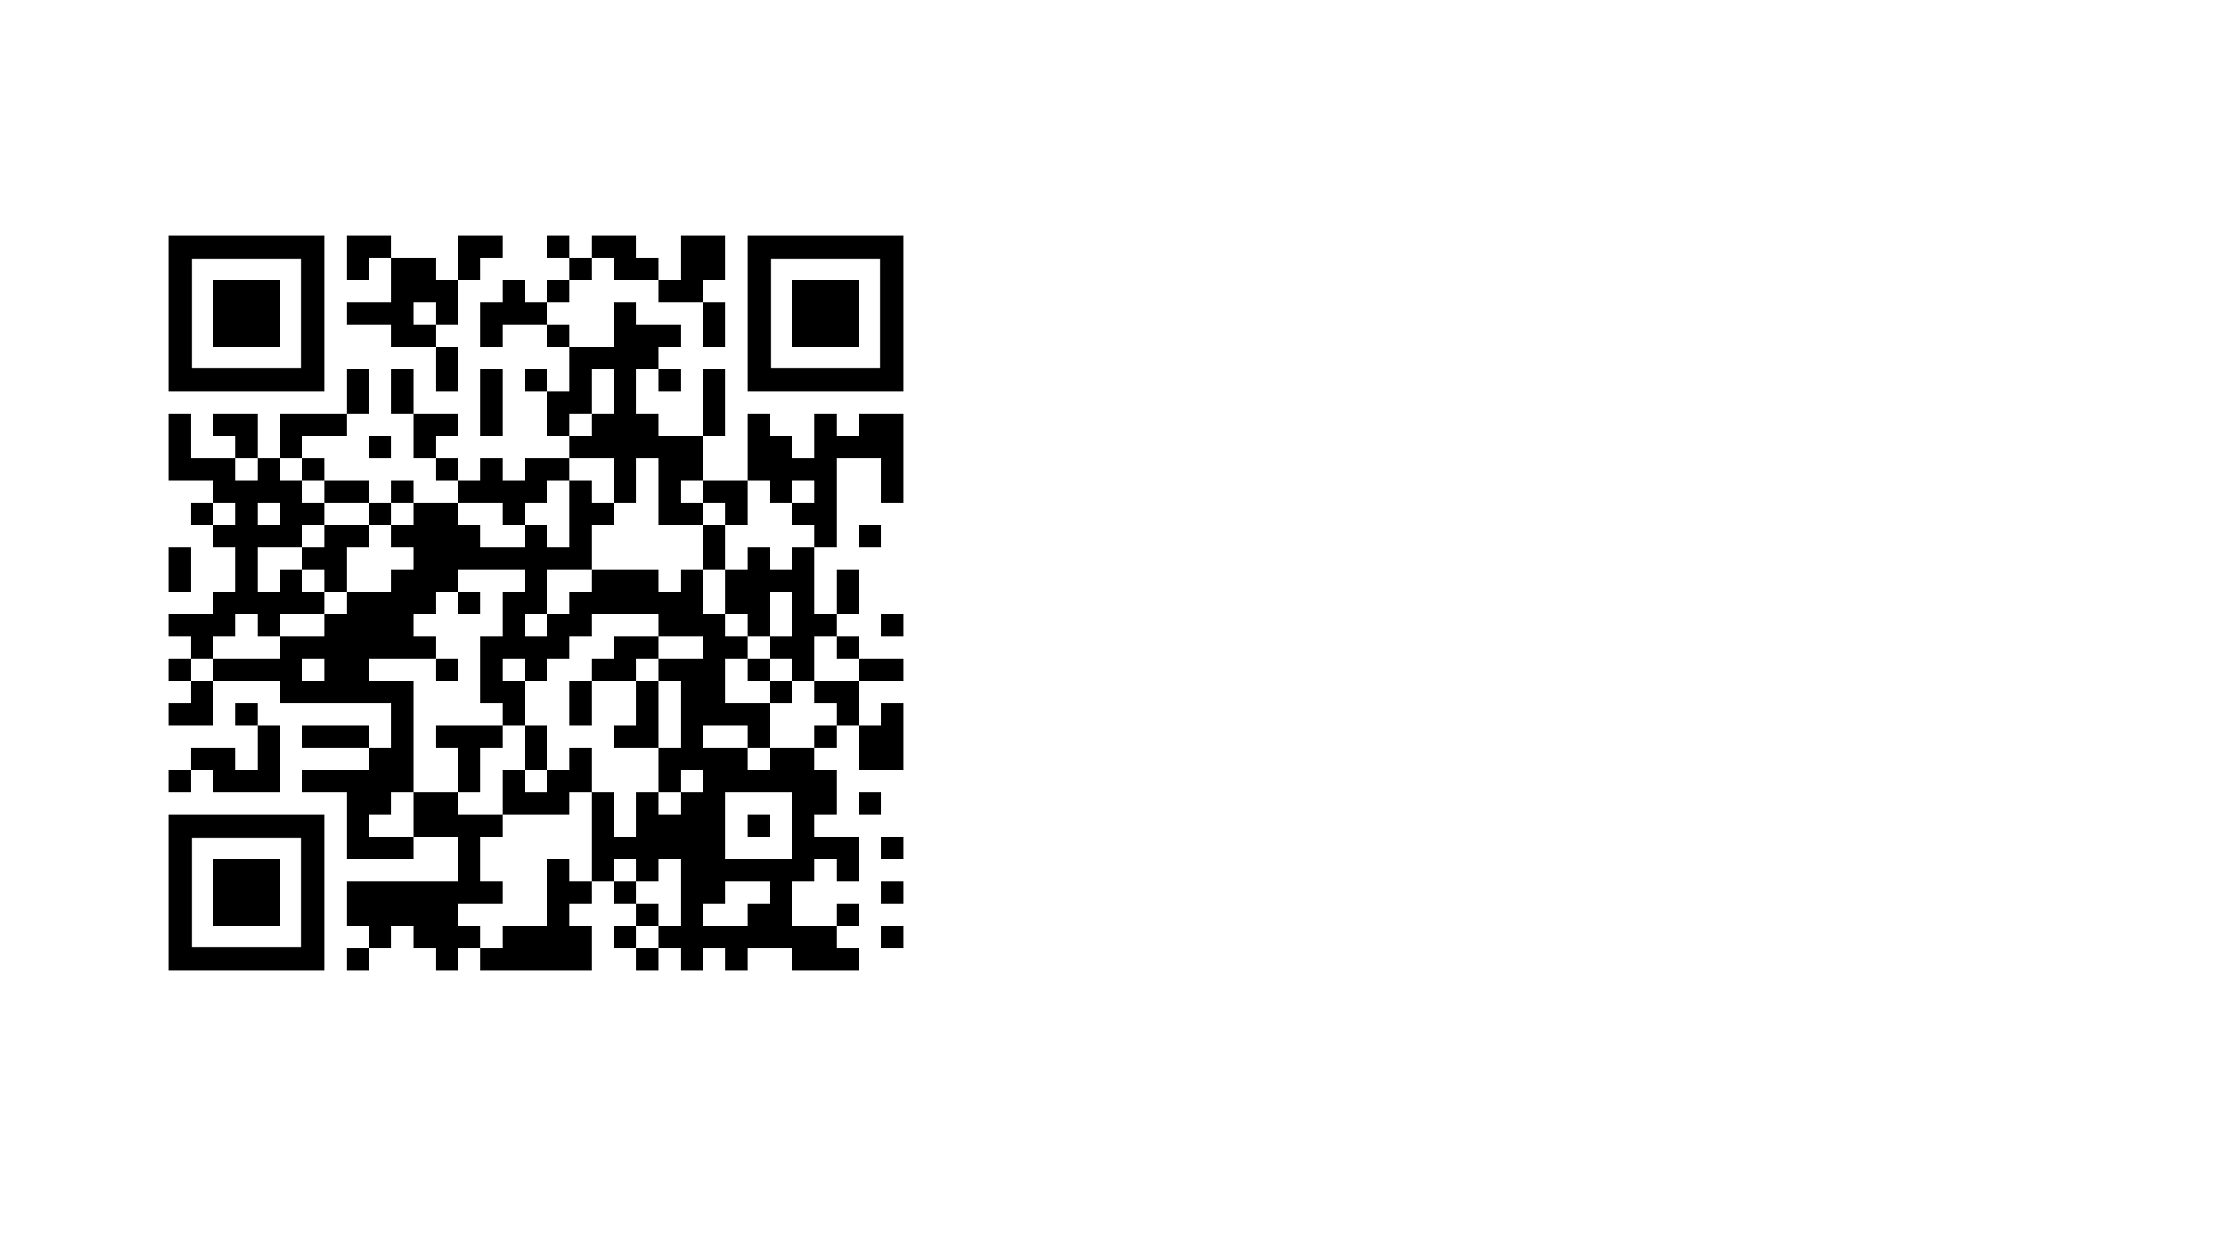